In [1]:
## Plot the results from the BNNs on one graph
from __future__ import annotations

import argparse
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import precision_recall_curve, average_precision_score

try:
    from sklearn.metrics import confusion_matrix
except ImportError as exc:  # pragma: no cover
    raise SystemExit("This script needs scikit-learn: pip install scikit-learn") from exc

In [2]:
def load_npz(path: Path) -> dict[str, np.ndarray]:
    with np.load(path, allow_pickle=True) as data:
        return {key: data[key] for key in data.files}

In [3]:
raw_EF = load_npz("EF_MVN_prior0pt5_test_posterior_predictive.npz")
raw_LF = load_npz("LF_MVN_prior0pt5_test_posterior_predictive.npz")


In [4]:
BNN_results_EF = {
    "probs_samples": np.stack(
        [raw_EF["posterior_class0_probs"], raw_EF["posterior_class1_probs"]],
        axis=-1,
    ),
    "probs_mean": np.column_stack(
        [raw_EF["posterior_mean_class0"], raw_EF["posterior_mean_class1"]]
    ),
    "labels": raw_EF["labels"],
}
ytest_EF = BNN_results_EF["labels"]

In [5]:
BNN_results_LF = {
    "probs_samples": np.stack(
        [raw_LF["posterior_class0_probs"], raw_LF["posterior_class1_probs"]],
        axis=-1,
    ),
    "probs_mean": np.column_stack(
        [raw_LF["posterior_mean_class0"], raw_LF["posterior_mean_class1"]]
    ),
    "labels": raw_LF["labels"],
}
ytest_LF = BNN_results_LF["labels"]

In [13]:
def normalize_probs(probs: np.ndarray) -> np.ndarray:
    """Return posterior probabilities as shape (S,N,K), or mean probs as (N,K)."""
    probs = np.asarray(probs)
    print(probs.ndim)
    if probs.ndim == 1:
        return np.column_stack([1.0 - probs, probs])

    if probs.ndim == 2:
        # Ambiguous: either (S,N) binary posterior samples or (N,K) mean probs.
        # Caller decides by context. Here, if columns sum roughly to 1, treat as (N,K).
        row_sums = probs.sum(axis=1)
        if probs.shape[1] > 2 and np.allclose(row_sums, 1.0, atol=1e-3):
            return probs
        if probs.shape[1] == 2 and np.allclose(row_sums, 1.0, atol=1e-3):
            return probs
        # Otherwise binary posterior samples (S,N).
        return np.stack([1.0 - probs, probs], axis=-1)

    if probs.ndim == 3:
        if probs.shape[-1] == 1:
            p = probs[..., 0]
            return np.stack([1.0 - p, p], axis=-1)
        return probs

    raise ValueError(f"Expected probability array with ndim 1, 2, or 3; got shape {probs.shape}")

# Look at posterior probabilities for random test cases
def plot_random_class_probabilities_bayesian(
    results: dict[str, np.ndarray],
    posterior_probs: np.ndarray | None,
    num_classes: int,
    title: str,
    out_path: Path,
    dpi: int,
    n_random: int,
    seed: int,
    data_ids: np.ndarray | None
) -> None:
    """
    Plot posterior PDFs of class probabilities for random test samples.

    For binary classification, each selected test sample gets its own plot with
    two PDFs: one for class 0 probability and one for class 1 probability.

    For multiclass classification, each selected test sample gets its own plot
    with one PDF per class.

    The plot title includes the true class when results contains y_true, y_test,
    true_class, true_classes, or labels.
    """
    ci_high_thresh = 0.2
    ci_low_thresh   = 0.5
    decision_out = ['No SHD','SHD','inconclusive']
    if posterior_probs is None:
        print(
            f"[skip] {title}: posterior probability samples were not saved. "
            "Need probs_samples with shape (S, N, K) to plot PDFs."
        )
        return

    p = normalize_probs(posterior_probs)

    if p.ndim != 3:
        print(f"[skip] {title}: posterior_probs could not be interpreted as shape (S,N,K).")
        return

    true_labels = None
    for key in ("y_true", "y_test", "true_class", "true_classes", "labels"):
        if key in results:
            true_labels = np.asarray(results[key])
            break

    n_samples, n_obs, inferred_num_classes = p.shape

    if true_labels is not None and len(true_labels) != n_obs:
        print(
            f"[warning] {title}: found true labels with length {len(true_labels)}, "
            f"but posterior_probs has N={n_obs}. Not using true labels in titles."
        )
        true_labels = None

    if inferred_num_classes != num_classes:
        print(
            f"[warning] {title}: num_classes={num_classes}, "
            f"but posterior_probs has K={inferred_num_classes}. Using K={inferred_num_classes}."
        )
        num_classes = inferred_num_classes

    rng = np.random.default_rng(seed)
    chosen = rng.choice(n_obs, size=min(n_random, n_obs), replace=False)
    if (len(data_ids)>0):
        chosen=rng.choice(data_ids, size=min(n_random, n_obs), replace=False)
    class_ids = np.arange(num_classes)
    for obs_idx in chosen:
        decision_plot = decision_out[0]
        BNN_pred = 0
        fig, ax = plt.subplots(figsize=(6, 4))
        for k in class_ids:
            vals = np.asarray(p[:, obs_idx, k], dtype=float)
            vals = vals[np.isfinite(vals)]

            if vals.size < 2:
                continue

            ax.hist(
                vals,
                bins=30,
                density=True,
                alpha=0.35,
                label=f"Class {decision_out[k]}",
            )

            mean_k = np.mean(vals)
            

            var_k  = np.var(vals)
            ci_low, ci_high = np.percentile(vals, [2.5, 97.5])
            if (k==1):
                if (ci_high<=ci_high_thresh):
                    decision_plot = decision_out[0]
                elif (ci_low>=ci_low_thresh):
                    decision_plot = decision_out[1]
                else:
                    decision_plot=decision_out[2]
                print(f"sample {obs_idx} class {k} has ci_high={ci_high} and ci_low={ci_low}: decision:{decision_plot}")
 


            coeff_var = mean_k/np.sqrt(var_k)

            # ax.axvline(mean_k, linestyle="--", linewidth=1.5)
            
        if true_labels is not None:
            if (true_labels[obs_idx]==0):
                true_class_text = "True class: No SHD"
            else:
                true_class_text = "True class: SHD"
        else:
            true_class_text = "True class: unavailable"

        ax.set_xlim(0, 1)
        ax.set_xlabel("Class probability")
        ax.set_ylabel("Posterior density")
        ax.axvline(ci_low_thresh, color='r',linestyle="--", linewidth=2.0,label='threshold: SHD')
        ax.axvline(ci_high_thresh, color='m',linestyle="--", linewidth=2.0, label='threshold: no SHD')
        ax.set_title(
            f"{title}\n"
            f"Test sample {obs_idx} | {true_class_text}\n"
            f"Decision: {decision_plot}"
        )
        ax.grid(True, alpha=0.10)
        ax.legend(loc="best")

        fig.tight_layout()

        sample_out_path = f"{out_path}_sample_{obs_idx}_pdfs.png"
        fig.savefig(sample_out_path, dpi=dpi)
        # plt.close(fig)

        # print(f"[saved] {sample_out_path}")





In [14]:
# Try to find where probabilities change the most
probs_stack = np.array((BNN_results_EF['probs_mean'][:,1].flatten(),BNN_results_LF['probs_mean'][:,1].flatten()))
probs_var = np.var(probs_stack,axis=0)
probs_id = np.argsort(probs_var)
print(probs_stack[:,probs_id[1000:]].T)

[[0.7964643  0.7596666 ]
 [0.77406746 0.73724073]
 [0.7665506  0.8034524 ]
 ...
 [0.7604691  0.38954884]
 [0.8060605  0.41126168]
 [0.8717577  0.44704613]]


Generate plots for random data (good, bad, ugly)

2
sample 316 class 1 has ci_high=0.6959653362631798 and ci_low=0.15795319378376008: decision:inconclusive
sample 1851 class 1 has ci_high=0.9657494872808456 and ci_low=0.6003858149051666: decision:SHD
sample 621 class 1 has ci_high=0.9942047044634819 and ci_low=0.826006504893303: decision:SHD
sample 5010 class 1 has ci_high=0.8782523959875107 and ci_low=0.3225232206285: decision:inconclusive


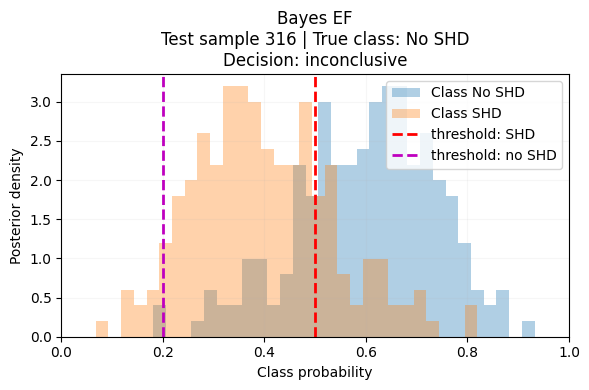

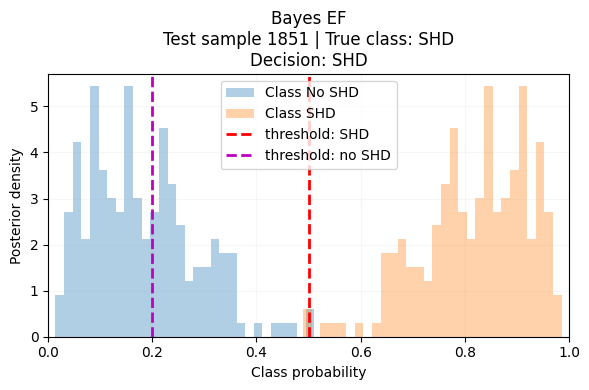

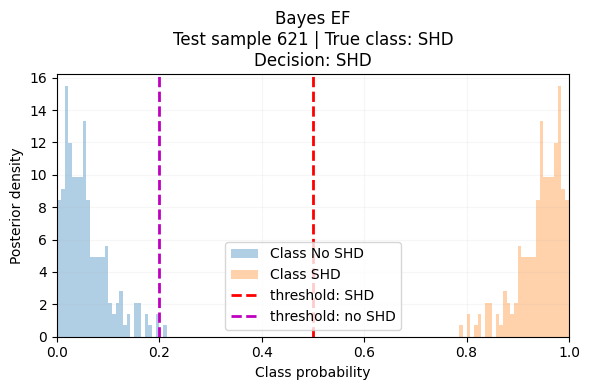

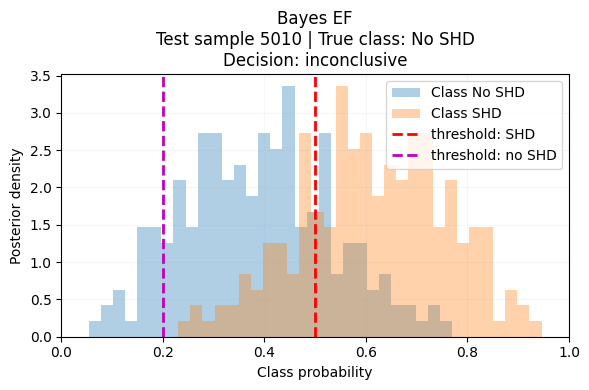

In [15]:
plot_random_class_probabilities_bayesian(results=BNN_results_EF,posterior_probs=raw_EF['posterior_class1_probs'],
                                         num_classes=2,title='Bayes EF',out_path='UQ_pred/EF_MVN_rand_',dpi=200,n_random=4,seed=42,data_ids=probs_id)



2
sample 316 class 1 has ci_high=0.3773687705397606 and ci_low=0.1871808595955372: decision:inconclusive
sample 1851 class 1 has ci_high=0.8738750502467155 and ci_low=0.6640529230237007: decision:SHD
sample 621 class 1 has ci_high=0.9886474773287773 and ci_low=0.8250790789723397: decision:SHD
sample 5010 class 1 has ci_high=0.693529410660267 and ci_low=0.3605344608426094: decision:inconclusive


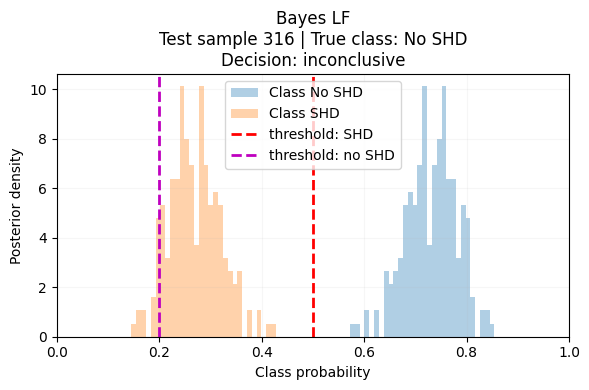

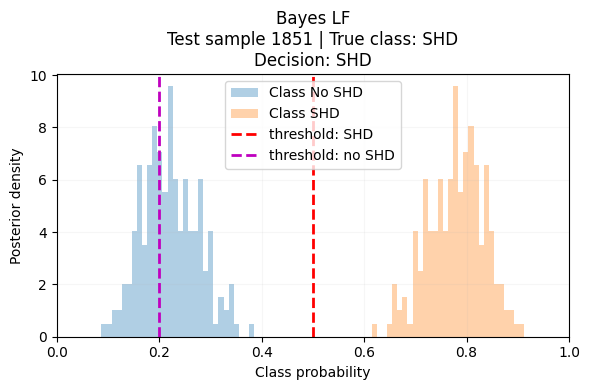

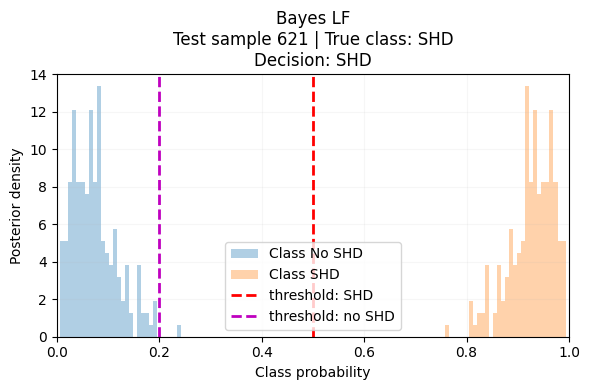

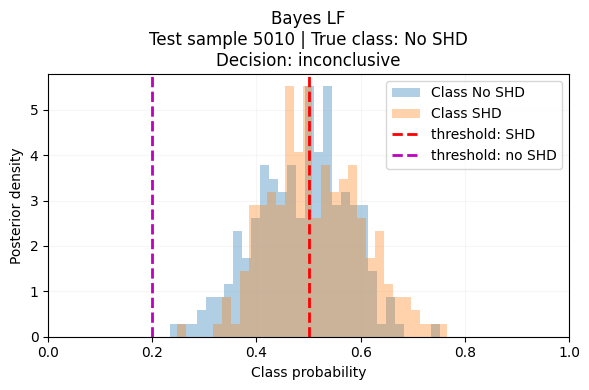

In [16]:
plot_random_class_probabilities_bayesian(results=BNN_results_LF,posterior_probs=raw_LF['posterior_class1_probs'],
                                         num_classes=2,title='Bayes LF',out_path='UQ_pred/LF_MVN_rand_',dpi=200,n_random=4,seed=42,data_ids=probs_id)

These plots look just at the data where the two models have a large variance

2
sample 229 class 1 has ci_high=0.9703141108155251 and ci_low=0.43229603096842767: decision:inconclusive
[1 0 1 ... 0 1 1]
sample 652 class 1 has ci_high=0.7202799871563916 and ci_low=0.14734822139143944: decision:inconclusive
[1 0 1 ... 0 1 1]
sample 302 class 1 has ci_high=0.7945993214845658 and ci_low=0.15396972559392452: decision:inconclusive
[1 0 1 ... 0 1 1]
sample 2825 class 1 has ci_high=0.955734646320343 and ci_low=0.46660385876894: decision:inconclusive
[1 0 1 ... 0 1 1]


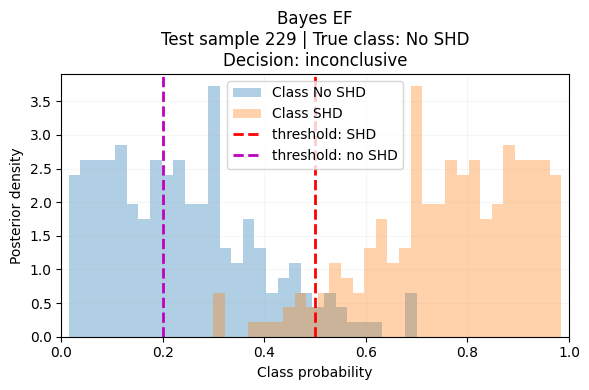

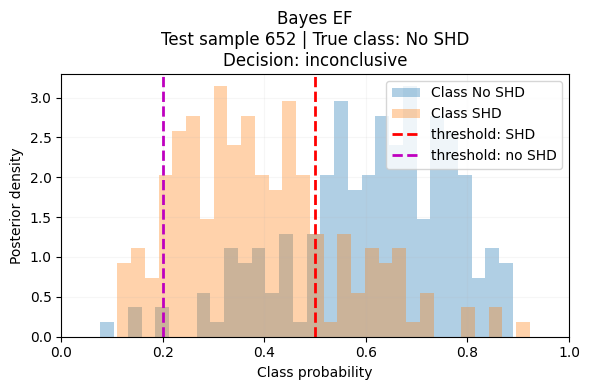

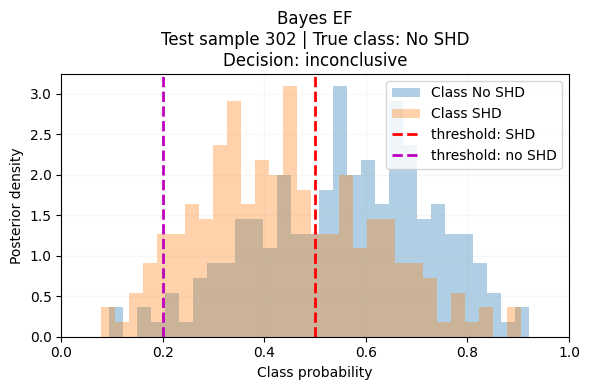

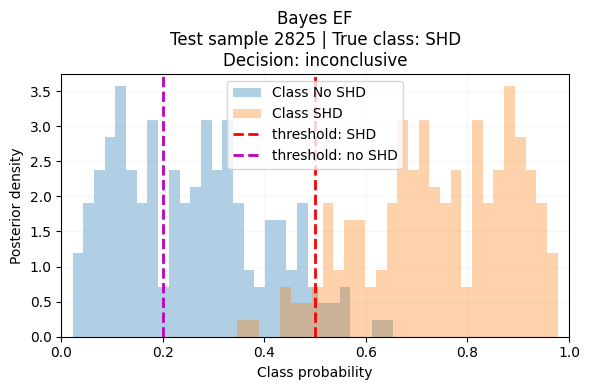

In [11]:
plot_random_class_probabilities_bayesian(results=BNN_results_EF,posterior_probs=raw_EF['posterior_class1_probs'],
                                         num_classes=2,title='Bayes EF',out_path='UQ_pred/EF_MVN_largediff_',dpi=200,n_random=4,seed=42,data_ids=probs_id[-200:])



2
sample 229 class 1 has ci_high=0.6638393923640251 and ci_low=0.33413010761141776: decision:inconclusive
[1 0 1 ... 0 1 1]
sample 652 class 1 has ci_high=0.2604816220700741 and ci_low=0.08656792882829904: decision:inconclusive
[1 0 1 ... 0 1 1]
sample 302 class 1 has ci_high=0.3128251150250435 and ci_low=0.12980569824576377: decision:inconclusive
[1 0 1 ... 0 1 1]
sample 2825 class 1 has ci_high=0.6293664827942849 and ci_low=0.38487170785665514: decision:inconclusive
[1 0 1 ... 0 1 1]


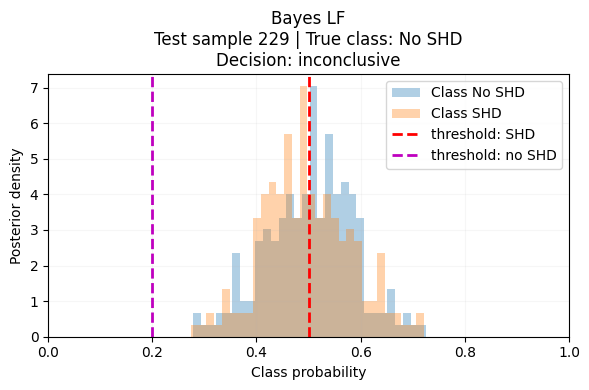

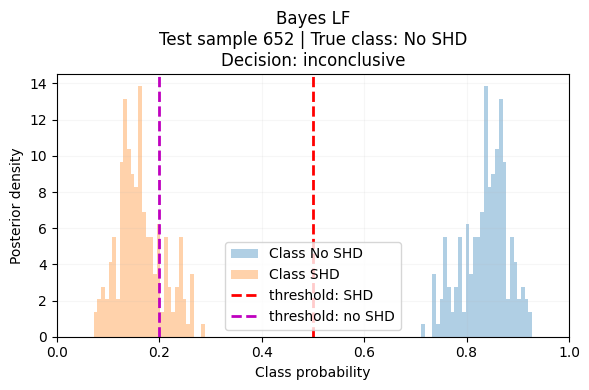

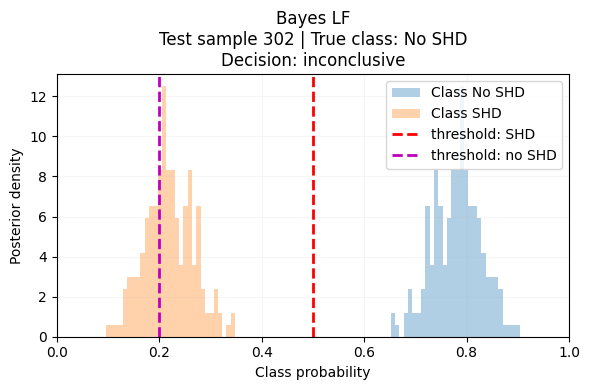

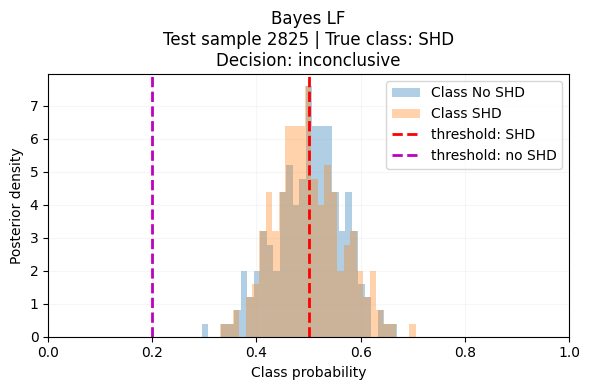

In [12]:
plot_random_class_probabilities_bayesian(results=BNN_results_LF,posterior_probs=raw_LF['posterior_class1_probs'],
                                         num_classes=2,title='Bayes LF',out_path='UQ_pred/LF_MVN_largediff_',dpi=200,n_random=4,seed=42,data_ids=probs_id[-200:])